In [1]:
# Load data, define features and both targets

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/kathmandu_features.csv")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df = df.sort_values("datetime_utc").reset_index(drop=True)

target_column = "target_pm25_next_1h"
feature_columns = [col for col in df.columns if col not in ["datetime_utc", target_column]]

X = df[feature_columns]
current_pm25 = df["pm25"]
y_absolute = df[target_column]
y_delta = y_absolute - current_pm25
dates = df["datetime_utc"]

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)

print(f"Features ({len(feature_columns)}): {feature_columns}")
print(f"Rows: {len(df)}")

Features (32): ['pm25', 'relativehumidity', 'temperature', 'um003', 'was_missing', 'hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'pm25_lag_1h', 'pm25_lag_2h', 'pm25_lag_6h', 'pm25_lag_7h', 'pm25_lag_8h', 'pm25_lag_9h', 'pm25_lag_24h', 'pm25_lag_48h', 'pm25_rolling_mean_6h', 'pm25_rolling_std_6h', 'pm25_rolling_mean_24h', 'pm25_rolling_std_24h', 'WS10M', 'WD10M', 'PRECTOTCORR', 'wind_dir_sin', 'wind_dir_cos', 'station_mid_baneshwor', 'station_teku']
Rows: 8343


In [2]:
# Train XGBoost on the delta target, per fold

xgb_results = []
xgb_predictions = []

for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_delta_train = y_delta.iloc[train_idx]
    y_absolute_test = y_absolute.iloc[test_idx]
    current_pm25_test = current_pm25.iloc[test_idx]
    dates_test = dates.iloc[test_idx]

    # Drop rows where the delta target itself is NaN (can't train on a missing target)
    train_valid_mask = ~y_delta_train.isna()
    X_train_valid = X_train[train_valid_mask]
    y_delta_train_valid = y_delta_train[train_valid_mask]

    model = xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train_valid, y_delta_train_valid)

    predicted_delta = model.predict(X_test)
    predicted_absolute = current_pm25_test.values + predicted_delta

    # current_pm25_test can be NaN for some rows; exclude those from scoring
    valid_mask = ~np.isnan(predicted_absolute)

    rmse = np.sqrt(mean_squared_error(y_absolute_test[valid_mask], predicted_absolute[valid_mask]))
    mae = mean_absolute_error(y_absolute_test[valid_mask], predicted_absolute[valid_mask])
    r2 = r2_score(y_absolute_test[valid_mask], predicted_absolute[valid_mask])

    xgb_results.append({"fold": fold_num, "rmse_xgb": rmse, "mae_xgb": mae, "r2_xgb": r2})
    xgb_predictions.append({
        "fold": fold_num, "dates": dates_test[valid_mask],
        "y_actual": y_absolute_test[valid_mask], "y_pred": predicted_absolute[valid_mask],
    })

    print(f"Fold {fold_num} ({dates_test.min().date()} to {dates_test.max().date()}): "
          f"RMSE={rmse:.2f} MAE={mae:.2f} R2={r2:.3f}")

xgb_df = pd.DataFrame(xgb_results)

Fold 1 (2025-12-24 to 2026-01-30): RMSE=20.89 MAE=13.93 R2=0.753
Fold 2 (2026-01-30 to 2026-04-04): RMSE=15.53 MAE=9.85 R2=0.816
Fold 3 (2026-04-04 to 2026-06-06): RMSE=17.75 MAE=10.24 R2=0.847
Fold 4 (2026-06-06 to 2026-07-30): RMSE=7.37 MAE=4.59 R2=0.800
Fold 5 (2026-07-30 to 2026-09-03): RMSE=6.54 MAE=4.28 R2=0.635


In [3]:
# Ablation: model (RF vs XGBoost) x target (absolute vs delta) + persistence
# Same folds, same training rows, same scoring rows for every approach.

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

xgb_params = dict(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=-1)

ablation_rows = []

for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_abs_train = y_absolute.iloc[train_idx]
    y_delta_train = y_delta.iloc[train_idx]
    y_test = y_absolute.iloc[test_idx].values
    pm25_test = current_pm25.iloc[test_idx].values

    train_mask = ~y_delta_train.isna().values   # rows where the delta target exists
    score_mask = ~np.isnan(pm25_test)           # rows where persistence is defined

    imputer = SimpleImputer(strategy="median")
    X_train_imp = imputer.fit_transform(X_train[train_mask])
    X_test_imp = imputer.transform(X_test)

    preds = {
        "xgb_delta": pm25_test + xgb.XGBRegressor(**xgb_params)
            .fit(X_train[train_mask], y_delta_train[train_mask]).predict(X_test),
        "xgb_absolute": xgb.XGBRegressor(**xgb_params)
            .fit(X_train[train_mask], y_abs_train[train_mask]).predict(X_test),
        "rf_delta": pm25_test + RandomForestRegressor(random_state=42, n_jobs=-1)
            .fit(X_train_imp, y_delta_train[train_mask]).predict(X_test_imp),
        "rf_absolute": RandomForestRegressor(random_state=42, n_jobs=-1)
            .fit(X_train_imp, y_abs_train[train_mask]).predict(X_test_imp),
        "persistence": pm25_test,
    }

    yt = y_test[score_mask]
    rmse_persist = np.sqrt(mean_squared_error(yt, pm25_test[score_mask]))

    for name, p in preds.items():
        rmse = np.sqrt(mean_squared_error(yt, p[score_mask]))
        ablation_rows.append({
            "fold": fold_num,
            "model": name,
            "rmse": rmse,
            "mae": mean_absolute_error(yt, p[score_mask]),
            "r2": r2_score(yt, p[score_mask]),
            "skill_vs_persist": 1 - rmse / rmse_persist,
        })

    print(f"Fold {fold_num} done ({score_mask.sum()} rows scored)")

ablation_df = pd.DataFrame(ablation_rows)

Fold 1 done (1388 rows scored)
Fold 2 done (1383 rows scored)
Fold 3 done (1377 rows scored)
Fold 4 done (1383 rows scored)
Fold 5 done (1388 rows scored)


In [4]:
print(ablation_df.shape)
ablation_df.head()

(25, 6)


,fold,model,rmse,mae,r2,skill_vs_persist
0,1,xgb_delta,20.890684,13.929569,0.752592,0.190192
1,1,xgb_absolute,23.968278,15.971643,0.674327,0.070892
2,1,rf_delta,20.516389,13.915423,0.761378,0.204701
3,1,rf_absolute,23.169835,15.469942,0.695663,0.101843
4,1,persistence,25.797088,17.773994,0.622732,0.000000


In [5]:
# Summary: per-fold RMSE, per-fold skill, and averages

model_order = ["xgb_delta", "xgb_absolute", "rf_delta", "rf_absolute", "persistence"]

rmse_table = ablation_df.pivot(index="fold", columns="model", values="rmse")[model_order]
skill_table = ablation_df.pivot(index="fold", columns="model", values="skill_vs_persist")[model_order[:-1]]

print(rmse_table)
print(skill_table)

model  xgb_delta  xgb_absolute   rf_delta  rf_absolute  persistence
fold                                                               
1      20.890684     23.968278  20.516389    23.169835    25.797088
2      15.526449     17.772677  19.776134    21.985521    18.837901
3      17.746897     18.576085  19.299521    19.826628    13.157190
4       7.367729     14.122538  12.576488     9.549971     7.738198
5       6.544789      6.452350   6.094153     6.488349     7.025198
model  xgb_delta  xgb_absolute  rf_delta  rf_absolute
fold                                                 
1       0.190192      0.070892  0.204701     0.101843
2       0.175787      0.056547 -0.049806    -0.167090
3      -0.348836     -0.411858 -0.466842    -0.506904
4       0.047875     -0.825042 -0.625248    -0.234134
5       0.068384      0.081542  0.132529     0.076418


In [6]:

print("=== RMSE per fold ===")
print(rmse_table.round(2).to_string())

print("\n=== Skill vs persistence per fold (above 0 = beats persistence) ===")
print(skill_table.round(3).to_string())

summary = ablation_df.groupby("model").agg(
    mean_rmse=("rmse", "mean"),
    mean_mae=("mae", "mean"),
    mean_r2=("r2", "mean"),
    mean_skill=("skill_vs_persist", "mean"),
    folds_beating_persist=("skill_vs_persist", lambda s: int((s > 0).sum())),
).loc[model_order]

print("\n=== Summary ===")
print(summary.round(3).to_string())

# Verdict
best = summary.drop("persistence")["mean_rmse"].idxmin()
print(f"\nBest model: {best} "
      f"(mean skill {summary.loc[best, 'mean_skill']:+.3f}, "
      f"beats persistence in {summary.loc[best, 'folds_beating_persist']}/{n_splits} folds)")

delta_gain = 1 - summary.loc["xgb_delta", "mean_rmse"] / summary.loc["xgb_absolute", "mean_rmse"]
print(f"Delta vs absolute target (XGBoost): {delta_gain * 100:.1f}% lower RMSE")

# Kept for compatibility with the save cell
final = pd.DataFrame({
    "fold": rmse_table.index,
    "rmse_xgb": rmse_table["xgb_delta"].values,
    "rmse_rf_delta": rmse_table["rf_delta"].values,
    "rmse_persist": rmse_table["persistence"].values,
    "r2_xgb": ablation_df[ablation_df.model == "xgb_delta"]["r2"].values,
    "r2_rf_delta": ablation_df[ablation_df.model == "rf_delta"]["r2"].values,
    "r2_persist": ablation_df[ablation_df.model == "persistence"]["r2"].values,
})

=== RMSE per fold ===
model  xgb_delta  xgb_absolute  rf_delta  rf_absolute  persistence
fold                                                              
1          20.89         23.97     20.52        23.17        25.80
2          15.53         17.77     19.78        21.99        18.84
3          17.75         18.58     19.30        19.83        13.16
4           7.37         14.12     12.58         9.55         7.74
5           6.54          6.45      6.09         6.49         7.03

=== Skill vs persistence per fold (above 0 = beats persistence) ===
model  xgb_delta  xgb_absolute  rf_delta  rf_absolute
fold                                                 
1          0.190         0.071     0.205        0.102
2          0.176         0.057    -0.050       -0.167
3         -0.349        -0.412    -0.467       -0.507
4          0.048        -0.825    -0.625       -0.234
5          0.068         0.082     0.133        0.076

=== Summary ===
              mean_rmse  mean_mae  mean_r2  m

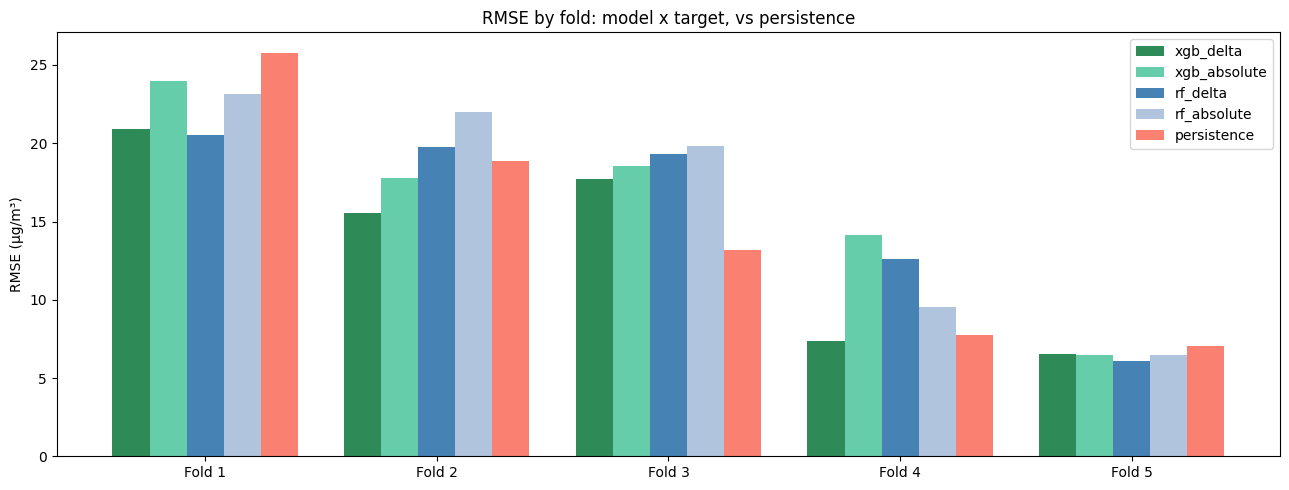

In [7]:
# RMSE per fold: all five approaches

colors = {
    "xgb_delta": "seagreen", "xgb_absolute": "mediumaquamarine",
    "rf_delta": "steelblue", "rf_absolute": "lightsteelblue",
    "persistence": "salmon",
}

x = np.arange(n_splits)
width = 0.16

plt.figure(figsize=(13, 5))
for i, name in enumerate(model_order):
    plt.bar(x + (i - 2) * width, rmse_table[name], width, label=name, color=colors[name])

plt.xticks(x, [f"Fold {i + 1}" for i in range(n_splits)])
plt.ylabel("RMSE (µg/m³)")
plt.title("RMSE by fold: model x target, vs persistence")
plt.legend()
plt.tight_layout()
plt.show()

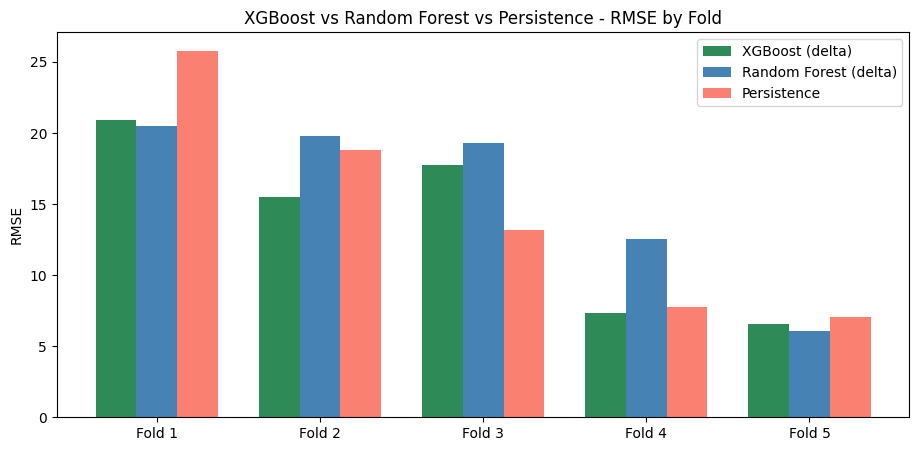

In [8]:
# RMSE per fold : all three approaches

x = np.arange(n_splits)
width = 0.25

plt.figure(figsize=(11, 5))
plt.bar(x - width, final["rmse_xgb"], width, label="XGBoost (delta)", color="seagreen")
plt.bar(x, final["rmse_rf_delta"], width, label="Random Forest (delta)", color="steelblue")
plt.bar(x + width, final["rmse_persist"], width, label="Persistence", color="salmon")
plt.xticks(x, [f"Fold {i+1}" for i in range(n_splits)])
plt.ylabel("RMSE")
plt.title("XGBoost vs Random Forest vs Persistence - RMSE by Fold")
plt.legend()
plt.show()

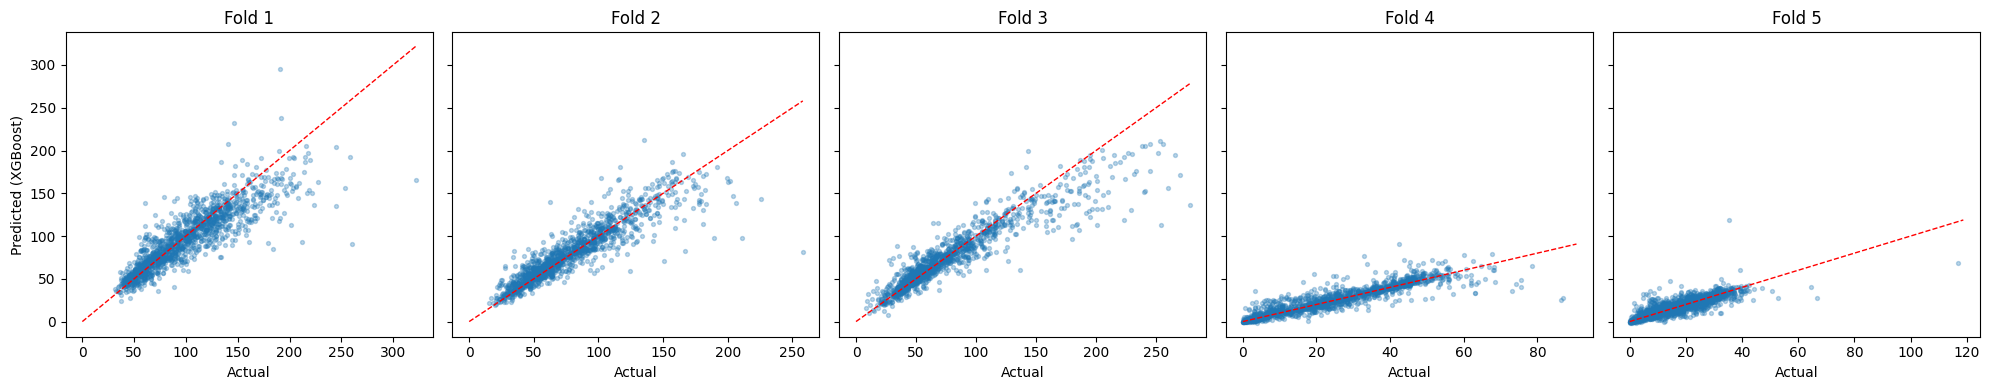

In [9]:
# Predicted vs actual, per fold (XGBoost)

fig, axes = plt.subplots(1, n_splits, figsize=(20, 4), sharey=True)

for i, fold_data in enumerate(xgb_predictions):
    ax = axes[i]
    ax.scatter(fold_data["y_actual"], fold_data["y_pred"], alpha=0.3, s=8)
    lims = [0, max(fold_data["y_actual"].max(), fold_data["y_pred"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(f"Fold {fold_data['fold']}")
    ax.set_xlabel("Actual")
    if i == 0:
        ax.set_ylabel("Predicted (XGBoost)")

plt.tight_layout()
plt.show()

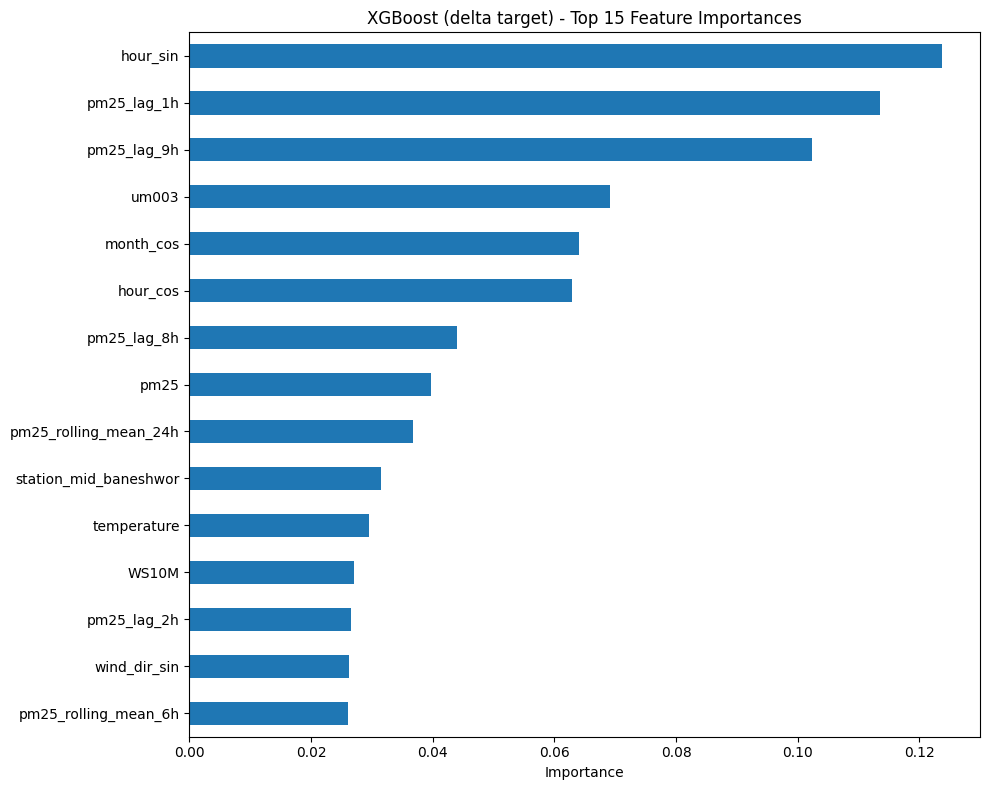

hour_sin                 0.123776
pm25_lag_1h              0.113517
pm25_lag_9h              0.102307
um003                    0.069083
month_cos                0.064090
hour_cos                 0.062807
pm25_lag_8h              0.043954
pm25                     0.039730
pm25_rolling_mean_24h    0.036781
station_mid_baneshwor    0.031545
temperature              0.029452
WS10M                    0.027077
pm25_lag_2h              0.026500
wind_dir_sin             0.026190
pm25_rolling_mean_6h     0.026018
dtype: float32


In [10]:
# Feature importance (XGBoost, trained on full data)

valid_mask_full = ~y_delta.isna()
X_valid = X[valid_mask_full]
y_delta_valid = y_delta[valid_mask_full]

final_xgb_model = xgb.XGBRegressor(
    n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=-1
)
final_xgb_model.fit(X_valid, y_delta_valid)

importances_xgb = pd.Series(final_xgb_model.feature_importances_, index=feature_columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances_xgb.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("XGBoost (delta target) - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances_xgb.head(15))

In [11]:
# Save the final model and results

import os
import joblib
import json

os.makedirs("../models", exist_ok=True)

joblib.dump(final_xgb_model, "../models/xgboost_delta_model.pkl")

main_model_summary = {
    "model": "XGBoost (delta target)",
    "validation": "TimeSeriesSplit (5 folds)",
    "xgb_avg_rmse": final["rmse_xgb"].mean(),
    "xgb_avg_r2": final["r2_xgb"].mean(),
    "rf_delta_avg_rmse": final["rmse_rf_delta"].mean(),
    "rf_delta_avg_r2": final["r2_rf_delta"].mean(),
    "persistence_avg_rmse": final["rmse_persist"].mean(),
    "persistence_avg_r2": final["r2_persist"].mean(),
    "hyperparameters": xgb_params,
    "ablation_summary": summary.round(4).to_dict(orient="index"),
}

with open("../models/main_model_results.json", "w") as f:
    json.dump(main_model_summary, f, indent=2, default=str)

print("Saved model to ../models/xgboost_delta_model.pkl")
print("Saved results to ../models/main_model_results.json")
print(main_model_summary)

Saved model to ../models/xgboost_delta_model.pkl
Saved results to ../models/main_model_results.json
{'model': 'XGBoost (delta target)', 'validation': 'TimeSeriesSplit (5 folds)', 'xgb_avg_rmse': np.float64(13.615309523165639), 'xgb_avg_r2': np.float64(0.7702932180960903), 'rf_delta_avg_rmse': np.float64(15.652537152967565), 'rf_delta_avg_r2': np.float64(0.6767834516550131), 'persistence_avg_rmse': np.float64(14.511115226016543), 'persistence_avg_r2': np.float64(0.7255070407611046), 'hyperparameters': {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'random_state': 42, 'n_jobs': -1}, 'ablation_summary': {'xgb_delta': {'mean_rmse': 13.6153, 'mean_mae': 8.5772, 'mean_r2': 0.7703, 'mean_skill': 0.0267, 'folds_beating_persist': 4}, 'xgb_absolute': {'mean_rmse': 16.1784, 'mean_mae': 11.083, 'mean_r2': 0.6354, 'mean_skill': -0.2056, 'folds_beating_persist': 3}, 'rf_delta': {'mean_rmse': 15.6525, 'mean_mae': 10.7256, 'mean_r2': 0.6768, 'mean_skill': -0.1609, 'folds_beating_persist'